<a href="https://colab.research.google.com/github/Togachisan/MATEMATICAS/blob/main/aguacates02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🥑 ¡Bienvenido al Concurso de Aguacates Gigantes (Versión Pandas)! 🥑

¿Deseas usar los datos precargados (p) o ingresar nuevos datos manualmente (m)? [p/m]: p

Usando datos precargados de la cosecha.

--- Definición de Rango Ideal ---
Ingresa el peso mínimo ideal (g) [Ej. 400]: 400
Ingresa el peso máximo ideal (g) [Ej. 600]: 600

📊 RESULTADOS DEL ANÁLISIS DE AGUACATES 🥑
Total de aguacates evaluados: 15
• Media (Promedio): 494.00 g
• Mediana: 490.00 g
• Moda: 490 g
• Desviación Estándar: 86.34 g
• Coeficiente de Variación (CV): 17.48%
• Asimetría (Skewness): 0.64
• Aguacate más ligero: 350.00 g
• Aguacate más pesado: 700.00 g
• En rango ideal (400.0g - 600.0g): 11 aguacates (73.3%)

📁 Reporte estructurado guardado exitosamente en 'analisis_aguacates.csv'
📁 Detalle individual guardado en 'detalle_aguacates.csv'


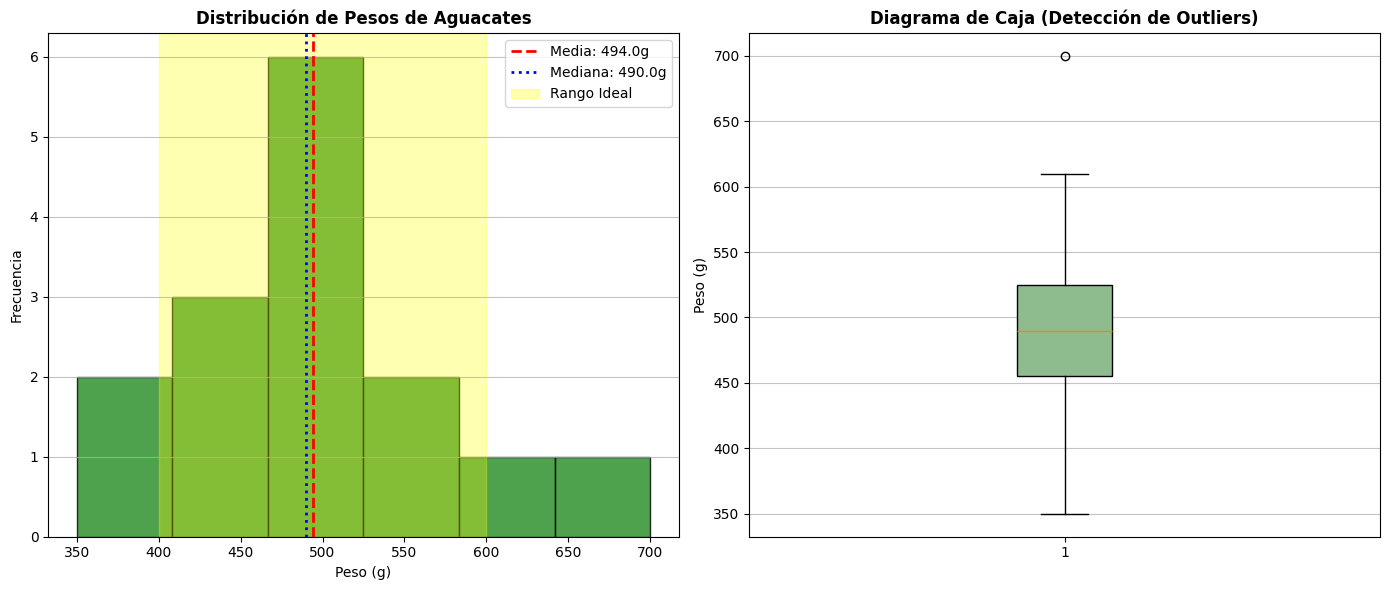

In [ ]:
import numpy as np
import statistics as stats
from scipy.stats import skew
import matplotlib.pyplot as plt
import pandas as pd

print("🥑 ¡Bienvenido al Concurso de Aguacates Gigantes 🥑\n")

# 1. Selección de datos: Precargados o manuales
opcion = input("¿Deseas usar los datos precargados (p) o ingresar nuevos datos manualmente (m)? [p/m]: ").strip().lower()

if opcion == 'm':
    aguacates = []
    print("\nIngresa los pesos de los aguacates en gramos. Escribe 'fin' cuando termines:")
    while True:
        entrada = input("Peso (g) o 'fin': ")
        if entrada.lower() == 'fin':
            break
        try:
            peso = float(entrada)
            if peso > 0:
                aguacates.append(peso)
            else:
                print("Por favor, ingresa un peso mayor a 0.")
        except ValueError:
            print("Entrada inválida. Ingresa un número válido o 'fin'.")

    if not aguacates:
        print("\nNo se ingresaron datos. Usando conjunto de datos precargados por defecto...")
        aguacates = [450, 520, 380, 610, 490, 530, 470, 420, 550, 480, 350, 700, 510, 490, 460]
else:
    aguacates = [450, 520, 380, 610, 490, 530, 470, 420, 550, 480, 350, 700, 510, 490, 460]
    print("\nUsando datos precargados de la cosecha.")

# Convertir a arreglo de numpy
datos = np.array(aguacates)

# 2. Rango ideal interactivo definido por el usuario
print("\n--- Definición de Rango Ideal ---")
try:
    rango_min = float(input("Ingresa el peso mínimo ideal (g) [Ej. 400]: "))
    rango_max = float(input("Ingresa el peso máximo ideal (g) [Ej. 600]: "))
except ValueError:
    print("Valores inválidos detectados. Usando rango por defecto: 400g - 600g.")
    rango_min, rango_max = 400.0, 600.0

# 3. Cálculos Estadísticos
n = len(datos)
media = np.mean(datos)
mediana = np.median(datos)
try:
    moda = stats.mode(datos)
except Exception:
    moda = "No única"

desviacion = np.std(datos, ddof=1)  # Desviación estándar muestral
cv = (desviacion / media) * 100     # Coeficiente de variación (%)
asimetria = skew(datos)             # Asimetría de la distribución
minimo = np.min(datos)
maximo = np.max(datos)

# Conteo dentro del rango ideal
en_rango = np.sum((datos >= rango_min) & (datos <= rango_max))
porcentaje_rango = (en_rango / n) * 100

# 4. Mostrar Resultados por Consola
print("\n" + "="*45)
print("📊 RESULTADOS DEL ANÁLISIS DE AGUACATES 🥑")
print("="*45)
print(f"Total de aguacates evaluados: {n}")
print(f"• Media (Promedio): {media:.2f} g")
print(f"• Mediana: {mediana:.2f} g")
print(f"• Moda: {moda} g")
print(f"• Desviación Estándar: {desviacion:.2f} g")
print(f"• Coeficiente de Variación (CV): {cv:.2f}%")
print(f"• Asimetría (Skewness): {asimetria:.2f}")
print(f"• Aguacate más ligero: {minimo:.2f} g")
print(f"• Aguacate más pesado: {maximo:.2f} g")
print(f"• En rango ideal ({rango_min}g - {rango_max}g): {en_rango} aguacates ({porcentaje_rango:.1f}%)")
print("="*45)

# 5. Guardar los resultados en un archivo CSV usando Pandas 📁
# Creamos un DataFrame con las métricas principales
df_resultados = pd.DataFrame({
    'Metrica': [
        'Total Evaluados', 'Media (g)', 'Mediana (g)', 'Moda (g)',
        'Desviacion Estandar (g)', 'Coeficiente de Variacion (%)',
        'Asimetria', 'Minimo (g)', 'Maximo (g)',
        'En Rango Ideal', 'Porcentaje en Rango (%)'
    ],
    'Valor': [
        n, round(media, 2), round(mediana, 2), str(moda),
        round(desviacion, 2), round(cv, 2),
        round(asimetria, 2), minimo, maximo,
        en_rango, round(porcentaje_rango, 2)
    ]
})

nombre_archivo_csv = "analisis_aguacates.csv"
df_resultados.to_csv(nombre_archivo_csv, index=False, encoding='utf-8-sig')
print(f"\n📁 Reporte estructurado guardado exitosamente en '{nombre_archivo_csv}'")

# (Opcional) Si también quieres un CSV con la lista de cada aguacate y si cumple o no con el rango:
df_detalle = pd.DataFrame({
    'Peso_Aguacate_g': datos,
    'En_Rango_Ideal': (datos >= rango_min) & (datos <= rango_max)
})
df_detalle.to_csv("detalle_aguacates.csv", index=False, encoding='utf-8-sig')
print(f"📁 Detalle individual guardado en 'detalle_aguacates.csv'")

# 6. Visualizaciones Avanzadas (Histograma y Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].hist(datos, bins=6, color='forestgreen', edgecolor='black', alpha=0.8)
axes[0].axvline(media, color='red', linestyle='dashed', linewidth=2, label=f'Media: {media:.1f}g')
axes[0].axvline(mediana, color='blue', linestyle='dotted', linewidth=2, label=f'Mediana: {mediana:.1f}g')
axes[0].axvspan(rango_min, rango_max, color='yellow', alpha=0.3, label='Rango Ideal')
axes[0].set_title('Distribución de Pesos de Aguacates', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Peso (g)', fontsize=10)
axes[0].set_ylabel('Frecuencia', fontsize=10)
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', alpha=0.75)

axes[1].boxplot(datos, vert=True, patch_artist=True, boxprops=dict(facecolor='darkseagreen', color='black'))
axes[1].set_title('Diagrama de Caja (Detección de Outliers)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Peso (g)', fontsize=10)
axes[1].grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()